# Ejercicio 1 · Rectificación métrica — versión paso a paso

Notebook de trabajo incremental: cada punto se añade tras explicarlo en el chat.

**Reglas del ejercicio:** núcleo en NumPy, sin OpenCV (OpenCV solo al final, para comparar).

**Formato de cada paso:**
1. Una celda **Markdown** con la teoría (si procede, de las diapositivas de clase) y la explicación de lo que se va a hacer en el paso.
2. Una celda de **código** largo pero entendible (una operación por línea, bucles explícitos). Al principio de la celda, un comentario `# Referencia:` indica de qué notebook existente se ha tomado como base; si es propio, lo dice.

| Punto | Estado |
|---|---|
| 0. Imports y configuración | ✅ |
| 1. Carga de la imagen | ✅ |
| 2. Puntos origen (4 esquinas) | ✅ |
| 3. Puntos destino | ✅ |
| 4. Homografía (DLT + SVD + Hartley) | ⏳ |
| 5. Warp propio + verificación de paralelismo | ⏳ |
| 6. Comparación con OpenCV |  ⏳ |

## 0. Imports y configuración

## 0. Imports y configuración

**Qué hacemos.** Importamos las librerías y fijamos el nombre de la foto.

* `numpy`: toda la matemática del ejercicio (el enunciado exige NumPy, sin OpenCV).
* `matplotlib`: dibujar la imagen y los resultados.
* `PIL`: **solo para leer** el archivo jpg. No es OpenCV, así que no incumple la restricción.

In [22]:
# numpy: para guardar la imagen como array y hacer todo el cálculo
import numpy as np

# matplotlib: para dibujar la imagen y los resultados
import matplotlib.pyplot as plt

# PIL: solo para LEER el archivo jpg (no es OpenCV)
from PIL import Image
from PIL import ImageOps

# Para que al imprimir matrices no salga notación científica
np.set_printoptions(suppress=True, precision=4)

# ---------------- CONFIGURACIÓN ----------------
# Nombre de la foto (en la misma carpeta que este notebook)
IMG_PATH = "foto_suelo.jpg"
# -----------------------------------------------

## 1. Carga de la imagen

Dividimos la carga en tres pasos pequeños: abrir el archivo, pasarlo a un array de NumPy y mostrarlo con una rejilla para poder leer coordenadas en píxeles. La foto mide 644 × 644 px, así que no hace falta reducirla.

### 1.1 Abrir la imagen y asegurar 3 canales (RGB)

**Qué hacemos.** Abrimos el archivo con PIL y lo convertimos a RGB para tener exactamente 3 canales (rojo, verde, azul). Si el archivo no existe, `Image.open` lanza un `FileNotFoundError` por sí solo.

*Teoría:* no procede, es solo lectura de datos.

In [23]:
# Referencia: Ejercicio1_Rectificacion.ipynb, apartado 1
#   (im = Image.open(IMG_PATH).convert("RGB"))
imagen_pil = Image.open(IMG_PATH)

print("Tamaño original (ancho, alto):", imagen_pil.size)
print("Modo de color original:       ", imagen_pil.mode)

# Nos aseguramos de que tenga exactamente 3 canales: Rojo, Verde, Azul
imagen_pil = imagen_pil.convert("RGB")

print("Modo de color tras convert:   ", imagen_pil.mode)

Tamaño original (ancho, alto): (644, 644)
Modo de color original:        RGB
Modo de color tras convert:    RGB


### 1.2 Convertir la imagen en un array de NumPy

**Qué hacemos.** Pasamos la imagen a un array `img` de forma `(alto, ancho, 3)`. A partir de aquí una imagen es una matriz de números y todo el cálculo es NumPy.

*Teoría (Clase 1, coordenadas):* un píxel se identifica por `(x, y)` = `(columna, fila)`, con el origen arriba a la izquierda y el eje $y$ **hacia abajo**. Ojo: en el array se indexa al revés, `img[fila, columna]` = `img[y, x]`. Esta diferencia importará al marcar puntos.

In [24]:
# Referencia: Ejercicio1_Rectificacion.ipynb, apartado 1 (img = np.asarray(im))
img = np.array(imagen_pil)

alto_img = img.shape[0]      # número de filas      (eje y)
ancho_img = img.shape[1]     # número de columnas   (eje x)
canales = img.shape[2]       # 3 canales: R, G, B

print("Forma del array img (alto, ancho, canales):", img.shape)
print("Alto:", alto_img, "| Ancho:", ancho_img, "| Canales:", canales)
print("Tipo de dato:", img.dtype)
print("Valor mínimo:", img.min(), "| Valor máximo:", img.max())

# Un píxel concreto: la esquina superior izquierda, fila 0, columna 0
print("Píxel img[0, 0] (R, G, B):", img[0, 0])

Forma del array img (alto, ancho, canales): (644, 644, 3)
Alto: 644 | Ancho: 644 | Canales: 3
Tipo de dato: uint8
Valor mínimo: 0 | Valor máximo: 255
Píxel img[0, 0] (R, G, B): [255 255 255]


### 1.3 Mostrar la imagen con una rejilla para leer coordenadas

**Qué hacemos.** Dibujamos la imagen con una rejilla y marcas cada 100 px en los ejes. Nos servirá en el paso 2 para leer a ojo las coordenadas de las esquinas.

*Teoría:* no procede.

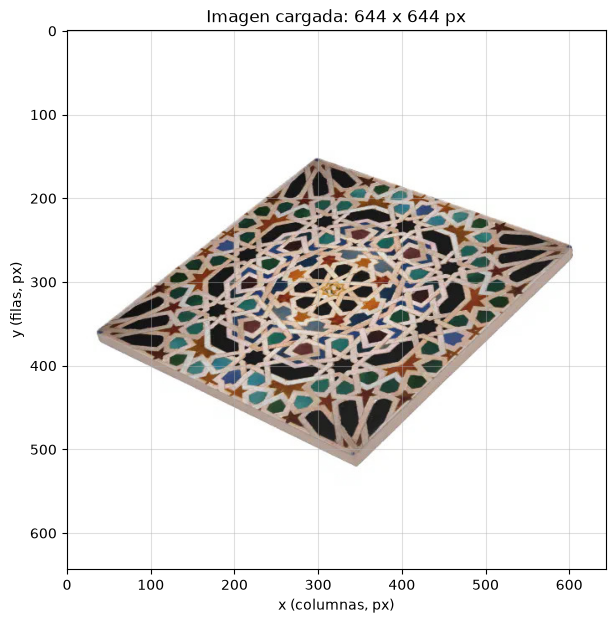

In [25]:
# Referencia: Ejercicio1_Rectificacion.ipynb, apartado 1 (plt.imshow + plt.grid)
fig, ax = plt.subplots(figsize=(10, 7))

ax.imshow(img)

# Marcas en los ejes cada 100 píxeles
marcas_x = list(range(0, ancho_img, 100))
marcas_y = list(range(0, alto_img, 100))
ax.set_xticks(marcas_x)
ax.set_yticks(marcas_y)

ax.grid(True, alpha=0.4)
ax.set_xlabel("x (columnas, px)")
ax.set_ylabel("y (filas, px)")
ax.set_title("Imagen cargada: " + str(ancho_img) + " x " + str(alto_img) + " px")

plt.show()

## 2. Puntos origen: las 4 esquinas de un rectángulo real

Hay que marcar en la foto las coordenadas $(x, y)$ en píxeles de **4 puntos que en el mundo real forman un rectángulo**. En nuestra foto son las 4 esquinas de la **cara superior** del azulejo (no las del canto lateral, que está en otro plano).

> **Teoría (Clase 1, diapositivas 23-24, "Homografías" y "Creando homografías").**
> * Una homografía tiene 9 parámetros, pero por homogeneidad **son 8** grados de libertad.
> * Un punto $P$ y su imagen $P'$ dan la condición $H\cdot P \equiv P'$. Quitando la proporcionalidad quedan **2 ecuaciones** (una por coordenada).
> * Con **4 puntos** tenemos $4\times 2 = 8$ ecuaciones: justo las que hacen falta. Por eso el enunciado pide exactamente 4.
> * Las 8 ecuaciones deben ser **independientes**: si 3 de los 4 puntos fueran colineales, no lo serían.

### 2.1 Definir las coordenadas de las 4 esquinas

**Qué hacemos.** Leemos de la rejilla del apartado 1.3 las coordenadas $(x, y)$ de las 4 esquinas y las guardamos en un array `PTS_IMG` de forma `(4, 2)`.

**El orden importa.** Los puntos origen y los de destino deben ir en el mismo orden: el punto $i$ de la foto se corresponde con el punto $i$ de la vista cenital. Usamos **TL → TR → BR → BL** (sentido horario). Como el azulejo está girado en la foto, "TL" es la esquina de la izquierda, "TR" la de arriba, "BR" la de la derecha y "BL" la de abajo.

> Un error de ±1 px en una esquina se amplifica en las zonas lejanas de la imagen rectificada, así que conviene marcarlas con precisión.

In [26]:
# Referencia: Ejercicio1_Rectificacion.ipynb, apartado 2 (array PTS_IMG con orden TL, TR, BR, BL)
# Coordenadas (x = columna, y = fila) leídas de la rejilla del apartado 1.3
esquina_TL = [39.0, 360.0]
esquina_TR = [299.0, 153.0]
esquina_BR = [601.0, 258.0]
esquina_BL = [345.0, 500.0]

# Las juntamos en un array de NumPy de forma (4, 2): 4 filas (esquinas) y 2 columnas (x, y)
PTS_IMG = np.array([esquina_TL, esquina_TR, esquina_BR, esquina_BL])

nombres_esquinas = ["TL", "TR", "BR", "BL"]

print("Forma de PTS_IMG:", PTS_IMG.shape)
print("Puntos origen (px):")
for i in range(4):
    nombre = nombres_esquinas[i]
    x = PTS_IMG[i, 0]
    y = PTS_IMG[i, 1]
    print("  ", nombre, ": x =", x, ", y =", y)

Forma de PTS_IMG: (4, 2)
Puntos origen (px):
   TL : x = 39.0 , y = 360.0
   TR : x = 299.0 , y = 153.0
   BR : x = 601.0 , y = 258.0
   BL : x = 345.0 , y = 500.0


### 2.2 Dibujar las esquinas sobre la imagen

**Qué hacemos.** Dibujamos el polígono que forman las 4 esquinas y sus etiquetas encima de la foto, para comprobar visualmente que están bien colocadas y en el orden previsto.

*Teoría:* no procede.

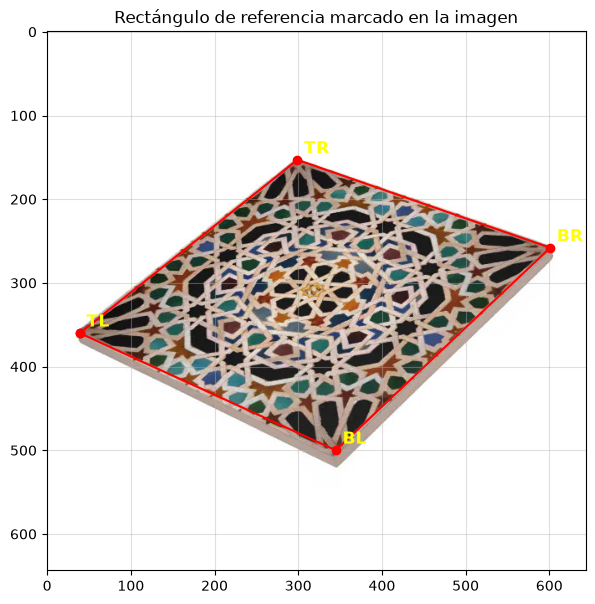

In [27]:
# Referencia: Ejercicio1_Rectificacion.ipynb, apartado 2
#   (plt.plot del polígono cerrado + plt.text con las etiquetas TL, TR, BR, BL)
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(img)

# Para cerrar el polígono repetimos el primer punto al final
xs_poligono = []
ys_poligono = []
for i in range(4):
    xs_poligono.append(PTS_IMG[i, 0])
    ys_poligono.append(PTS_IMG[i, 1])
xs_poligono.append(PTS_IMG[0, 0])
ys_poligono.append(PTS_IMG[0, 1])

ax.plot(xs_poligono, ys_poligono, "r-o")

# Etiqueta con el nombre de cada esquina
for i in range(4):
    ax.text(PTS_IMG[i, 0] + 8, PTS_IMG[i, 1] - 8, nombres_esquinas[i],
            color="yellow", fontsize=12, weight="bold")

ax.set_title("Rectángulo de referencia marcado en la imagen")
ax.grid(True, alpha=0.4)
plt.show()

### 2.3 Comprobación: que no haya 3 puntos colineales

**Qué hacemos.** Comprobamos con código la condición teórica de que los 4 puntos den 8 ecuaciones independientes. Para cada trío de puntos $A, B, C$ calculamos el área del triángulo:

$$\text{área} = \tfrac12\,\left|(B-A)\times(C-A)\right| = \tfrac12\,\left|b_x c_y - b_y c_x\right|$$

con $b = B-A$, $c = C-A$. Si el área es 0, los tres puntos están en la misma recta (colineales).

*Teoría (Clase 1, producto cruzado):* tres puntos son colineales cuando el producto cruzado de los vectores $B-A$ y $C-A$ es nulo.

In [28]:
# Referencia: propia (no hay equivalente en los notebooks existentes)
print("Comprobación de colinealidad (área de cada trío de puntos):")

hay_colineales = False

for i in range(4):
    for j in range(i + 1, 4):
        for k in range(j + 1, 4):
            A = PTS_IMG[i]
            B = PTS_IMG[j]
            C = PTS_IMG[k]

            vector_AB = B - A
            vector_AC = C - A

            cruce = vector_AB[0] * vector_AC[1] - vector_AB[1] * vector_AC[0]
            area = abs(cruce) / 2.0

            print("  ", nombres_esquinas[i], nombres_esquinas[j], nombres_esquinas[k],
                  "-> área =", area, "px²")

            # Menos de 1 px² de área = prácticamente colineales
            if area < 1.0:
                hay_colineales = True

if hay_colineales:
    print("¡ATENCIÓN! Hay 3 puntos casi colineales: el sistema sería inestable")
else:
    print("Correcto: ningún trío de puntos es colineal")

Comprobación de colinealidad (área de cada trío de puntos):
   TL TR BR -> área = 44907.0 px²
   TL TR BL -> área = 49871.0 px²
   TL BR BL -> área = 54946.0 px²
   TR BR BL -> área = 49982.0 px²
Correcto: ningún trío de puntos es colineal


### 2.4 Comprobación: que el orden sea sentido horario

**Qué hacemos.** Verificamos que TL → TR → BR → BL recorre el cuadrilátero en sentido horario, para que coincida con el orden de los puntos destino del paso 3. Usamos el **área con signo** (fórmula de Gauss):

$$\text{área con signo} = \tfrac12\sum_{i=0}^{3}\left(x_i\,y_{i+1} - x_{i+1}\,y_i\right)$$

En una imagen el eje $y$ va hacia abajo, así que un resultado **positivo** significa sentido horario.

*Teoría:* no procede (es una comprobación geométrica auxiliar).

In [29]:
# Referencia: propia (no hay equivalente en los notebooks existentes)
suma = 0.0
for i in range(4):
    siguiente = (i + 1) % 4          # después del último volvemos al primero
    x_i = PTS_IMG[i, 0]
    y_i = PTS_IMG[i, 1]
    x_s = PTS_IMG[siguiente, 0]
    y_s = PTS_IMG[siguiente, 1]
    suma = suma + (x_i * y_s - x_s * y_i)

area_con_signo = suma / 2.0
print("Área con signo del cuadrilátero:", area_con_signo, "px²")

if area_con_signo > 0:
    print("Correcto: orden TL -> TR -> BR -> BL en sentido horario")
else:
    print("¡ATENCIÓN! El orden es antihorario: revisa las esquinas")

Área con signo del cuadrilátero: 99853.0 px²
Correcto: orden TL -> TR -> BR -> BL en sentido horario


## 3. Puntos destino: el rectángulo perfecto, a escala real

Hay que decir **dónde queremos que caigan** las 4 esquinas en la vista cenital. Serán las esquinas de un rectángulo perfecto cuyas proporciones sean las del objeto real.

> **Teoría (Clase 1, diapositivas 25-27, "Ejemplo de uso: rectificación de perspectiva").**
> * Primero se identifican a mano las esquinas en la foto (paso 2).
> * Después se decide en qué posición queremos que acabe el objeto: se calculan las esquinas de ese cuadrado (en la diapositiva, $\{[50,80],[150,80],[150,180],[50,180]\}$).
> * Con las 4 correspondencias se plantea el sistema de **8 ecuaciones y 8 incógnitas** que da $H$ (paso 4).
>
> **Metrología plana (Clase 2).** Si elegimos una escala de $s$ píxeles por cm, la imagen rectificada deja de ser solo "bonita" y pasa a ser **métrica**: una distancia de $d$ píxeles en la salida equivale a $d/s$ cm reales.

### 3.1 Dimensiones reales y escala de salida

**Qué hacemos.** Definimos los datos físicos del rectángulo y la escala de la imagen de salida:

* `REAL_W_CM`, `REAL_H_CM`: ancho (lado TL→TR) y alto (lado TL→BL) reales del rectángulo, en cm.
* `PX_PER_CM`: píxeles de salida por cada cm real.
* `MARGIN_CM`: margen alrededor del rectángulo, para ver también un poco de lo que lo rodea.

> **Suposición.** No conocemos las medidas reales de este azulejo. Suponemos que es **cuadrado de 15 cm de lado**. Si no es cuadrado, la vista cenital saldrá estirada en una dirección. Con una foto propia habría que medirlo con una regla y cambiar estos dos valores.

In [ ]:
# Referencia: Ejercicio1_Rectificacion.ipynb, apartado 0 (variables REAL_W_CM, REAL_H_CM, PX_PER_CM, MARGIN_CM)
# Medidas reales (en cm) del rectángulo cuyas 4 esquinas marcamos en el paso 2
REAL_W_CM = 15.0     # ancho: lado TL -> TR   (SUPUESTO: azulejo cuadrado)
REAL_H_CM = 15.0     # alto:  lado TL -> BL   (SUPUESTO: azulejo cuadrado)

# Escala de la vista cenital: píxeles de salida por cada cm real
PX_PER_CM = 20.0

# Margen (en cm) alrededor del rectángulo en la imagen de salida
MARGIN_CM = 2.0

print("Rectángulo real:", REAL_W_CM, "x", REAL_H_CM, "cm")
print("Escala:", PX_PER_CM, "px/cm  ->  1 px =", 1.0 / PX_PER_CM, "cm")
print("Margen:", MARGIN_CM, "cm")

### 3.2 Esquinas destino y tamaño de la imagen de salida

**Qué hacemos.** Calculamos las 4 esquinas destino con el **mismo orden** que los puntos origen (TL, TR, BR, BL). Si el rectángulo mide $W \times H$ cm, la escala es $s$ px/cm y el margen es $m$ cm:

$$(x', y') \in \{(m,\,m),\ (m+W,\,m),\ (m+W,\,m+H),\ (m,\,m+H)\}\cdot s$$

El tamaño de la imagen de salida es

$$\text{ancho} = (W + 2m)\cdot s \qquad \text{alto} = (H + 2m)\cdot s$$

Así, la esquina TL queda en $(m\cdot s,\ m\cdot s)$ y deja un margen en los cuatro lados.

In [ ]:
# Referencia: Ejercicio1_Rectificacion.ipynb, apartado 3
#   (PTS_DST = (corners_cm + MARGIN_CM) * PX_PER_CM, y OUT_W / OUT_H)

# Esquinas del rectángulo en cm, con el origen en TL, mismo orden que PTS_IMG: TL, TR, BR, BL
esquinas_cm = np.array([[0.0,        0.0],
                        [REAL_W_CM,  0.0],
                        [REAL_W_CM,  REAL_H_CM],
                        [0.0,        REAL_H_CM]])

# Pasamos de cm a píxeles de salida: (cm + margen) * escala, esquina a esquina
PTS_DST = np.zeros((4, 2))
for i in range(4):
    x_cm = esquinas_cm[i, 0]
    y_cm = esquinas_cm[i, 1]
    PTS_DST[i, 0] = (x_cm + MARGIN_CM) * PX_PER_CM
    PTS_DST[i, 1] = (y_cm + MARGIN_CM) * PX_PER_CM

# Tamaño de la imagen de salida (en píxeles, redondeado a entero)
OUT_W = int(round((REAL_W_CM + 2 * MARGIN_CM) * PX_PER_CM))
OUT_H = int(round((REAL_H_CM + 2 * MARGIN_CM) * PX_PER_CM))

print("Puntos destino (px):")
for i in range(4):
    print("  ", nombres_esquinas[i], ": x' =", PTS_DST[i, 0], ", y' =", PTS_DST[i, 1])

print("\nImagen de salida:", OUT_W, "x", OUT_H, "px")

### 3.3 Comprobación: el destino es un rectángulo con las proporciones reales

**Qué hacemos.** Antes de calcular $H$, verificamos que `PTS_DST` es lo que queremos: lados opuestos de igual longitud, ángulos rectos y relación ancho/alto igual a la real. Así, si algo falla en el paso 4 o 5, sabemos que el error no viene de aquí. También dibujamos el destino sobre un lienzo del tamaño de la imagen de salida.

*Teoría:* no procede (comprobación auxiliar). Recuerda que $d$ píxeles equivalen a $d/s$ cm.

In [ ]:
# Referencia: propia (no hay equivalente en los notebooks existentes)
# Longitud de cada lado en píxeles de salida y en cm reales
print("Longitud de los lados del destino:")
for i in range(4):
    siguiente = (i + 1) % 4
    dx = PTS_DST[siguiente, 0] - PTS_DST[i, 0]
    dy = PTS_DST[siguiente, 1] - PTS_DST[i, 1]
    longitud_px = np.sqrt(dx * dx + dy * dy)
    longitud_cm = longitud_px / PX_PER_CM
    print("  ", nombres_esquinas[i], "->", nombres_esquinas[siguiente],
          ":", longitud_px, "px =", longitud_cm, "cm")

# Ángulo en la esquina TL entre los lados TL->TR y TL->BL (debe ser 90°)
lado_ancho = PTS_DST[1] - PTS_DST[0]
lado_alto = PTS_DST[3] - PTS_DST[0]
producto_escalar = lado_ancho[0] * lado_alto[0] + lado_ancho[1] * lado_alto[1]
print("\nProducto escalar de los lados en TL (0 = ángulo recto):", producto_escalar)

# Relación ancho / alto: debe coincidir con la real
relacion_destino = np.linalg.norm(lado_ancho) / np.linalg.norm(lado_alto)
relacion_real = REAL_W_CM / REAL_H_CM
print("Relación ancho/alto  destino:", relacion_destino, " | real:", relacion_real)

# Dibujo del destino sobre un lienzo blanco del tamaño de la imagen de salida
lienzo = np.ones((OUT_H, OUT_W, 3), dtype=np.uint8) * 255

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(lienzo)

xs_dst = []
ys_dst = []
for i in range(4):
    xs_dst.append(PTS_DST[i, 0])
    ys_dst.append(PTS_DST[i, 1])
xs_dst.append(PTS_DST[0, 0])
ys_dst.append(PTS_DST[0, 1])

ax.plot(xs_dst, ys_dst, "r-o")
for i in range(4):
    ax.text(PTS_DST[i, 0] + 6, PTS_DST[i, 1] - 6, nombres_esquinas[i],
            color="blue", fontsize=12, weight="bold")

ax.set_title("Esquinas destino en la imagen de salida (" + str(OUT_W) + " x " + str(OUT_H) + " px)")
ax.grid(True, alpha=0.4)
plt.show()